# Klasifikasi severity jerawat — Custom CNN from scratch

Notebook ini membangun **CNN sendiri dengan bobot acak** menggunakan PyTorch untuk
empat label ACNE04: `mild`, `moderate`, `severe`, dan `very_severe`.
Metode: supervised image classification dengan **weighted cross-entropy**.
Tidak memuat model atau bobot pretrained.

Jalankan sel dari atas ke bawah. GPU Colab disarankan. Download dataset asli sekitar
1,13 GB; cache dan dependensi membutuhkan ruang tambahan. Sel training menjalankan
pelatihan sungguhan, jadi waktu dan hasil bergantung perangkat.

Hasil notebook adalah baseline penelitian. Tidak ada target accuracy yang dijamin.
Dataset ini tidak menyediakan kelas kulit tanpa jerawat dan belum memvalidasi
kemampuan diagnosis pada foto pengguna di luar ACNE04.

Sumber: [kartu dataset](https://huggingface.co/datasets/Layered-Labs/ACNE04) dan
[paper asli ACNE04](https://openaccess.thecvf.com/content_ICCV_2019/html/Wu_Joint_Acne_Image_Grading_and_Counting_via_Label_Distribution_Learning_ICCV_2019_paper.html).
Ikuti ketentuan akademik/penelitian pada kartu dataset.


## 1. Instalasi

Jalankan sel berikut jika dependensi belum tersedia. Di lokal, boleh memakai
`requirements.txt` dan melewati sel ini. PyTorch dan torchvision harus merupakan
pasangan versi yang kompatibel. Restart kernel jika instalasi meminta restart.


In [ ]:
%pip install "torch>=2.3,<3" "torchvision>=0.18,<1" "datasets>=3,<5" "numpy>=1.26,<3" "pandas>=2.2,<3" "scikit-learn>=1.4,<2" "matplotlib>=3.8,<4" "Pillow>=10.4,<13" "tqdm>=4.66,<5"


In [ ]:
import io
import json
import math
import random
import hashlib
import platform
from pathlib import Path
from datetime import datetime
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from IPython.display import display

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from datasets import load_dataset, concatenate_datasets, Image as HFImage
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, cohen_kappa_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

CLASS_NAMES = ["mild", "moderate", "severe", "very_severe"]
LABELS = list(range(len(CLASS_NAMES)))
VERSIONS = {
    name: version(name)
    for name in ["torch", "torchvision", "datasets", "numpy", "pandas",
                 "scikit-learn", "matplotlib", "Pillow"]
}
print("Python:", platform.python_version())
print("Library versions:", VERSIONS)


Python: 3.13.15
Library versions: {'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'datasets': '4.8.5', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0', 'Pillow': '11.3.0'}


## 2. Konfigurasi dan reproducibility

Mulai dengan resolusi 224 dan batch 16. Jika GPU kehabisan memori, turunkan
batch menjadi 8. Untuk mencoba alur terlebih dahulu, ubah `epochs` menjadi 2;
hasil percobaan singkat tersebut tidak menunjukkan performa akhir.

Normalisasi memakai mean/std tetap 0,5, bukan statistik test. Seed membantu
reproducibility, tetapi hasil lintas perangkat/versi masih dapat berbeda.
Setiap eksekusi sel ini membuat folder run baru agar checkpoint tidak tertukar.


In [ ]:
CFG = {
    "dataset_id": "Layered-Labs/ACNE04",
    "dataset_revision": "main",
    "seed": 42,
    "image_size": 224,
    "batch_size": 16,
    "epochs": 100,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "validation_fraction": 0.20,
    "early_stopping_patience": 15,
    "lr_patience": 5,
    "gradient_clip": 1.0,
    "dropout": 0.40,
    "num_workers": 0,  # Aman untuk notebook Windows.
    "use_amp": True,   # Hanya aktif pada CUDA.
    "mean": [0.5, 0.5, 0.5],
    "std": [0.5, 0.5, 0.5],
    "padding_rgb": [128, 128, 128],
}
assert CFG["epochs"] >= 1 and CFG["batch_size"] >= 1
assert 0 < CFG["validation_fraction"] < 1

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything(CFG["seed"])
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path("acne04_data").resolve()
RUN_DIR = Path("acne04_runs") / ("run_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
RUN_DIR = RUN_DIR.resolve()
DATA_DIR.mkdir(parents=True, exist_ok=True)
RUN_DIR.mkdir(parents=True, exist_ok=False)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CPU aktif. Pelatihan penuh akan lebih lambat daripada GPU.")
print("Folder hasil:", RUN_DIR)


Device: cuda
GPU: Tesla T4
Folder hasil: /content/acne04_runs/run_20261018_172805_061084


## 3. Ambil dataset dan validasi schema

Repository ini menyimpan semua baris pada container Hugging Face `train`;
membership benchmark berada di **kolom** `split`.
Gunakan `level` 0–3 sebagai target, bukan `lesion_count_label`.
Canonical split pada kartu dataset adalah 1.165 train / 292 test sebelum audit.

Notebook memeriksa kolom tersebut alih-alih menganggap container `train`
sudah merupakan training set. Catat fingerprint, versi, dan nama file agar
eksperimen dapat dilacak; pin `dataset_revision` ke commit jika diperlukan.


In [ ]:
hf_dataset = load_dataset(
    CFG["dataset_id"],
    revision=CFG["dataset_revision"],
    cache_dir=str(DATA_DIR / "huggingface"),
)
parts = list(hf_dataset.values())
raw_dataset = parts[0] if len(parts) == 1 else concatenate_datasets(parts)
required_columns = {"image", "file_name", "level", "severity", "split"}
missing = required_columns - set(raw_dataset.column_names)
if missing:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing}")
DATASET_FINGERPRINT = str(raw_dataset._fingerprint)
# Decode manual untuk audit piksel dan konsistensi orientasi EXIF.
raw_dataset = raw_dataset.cast_column("image", HFImage(decode=False))
print(hf_dataset)
print("Total gambar:", len(raw_dataset))
print("Fingerprint:", DATASET_FINGERPRINT)


README.md:   0%|          | 0.00/8.60k [00:00<?, ?B/s]

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  415MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  410MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  305MB            

data/train-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1457 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'file_name', 'level', 'severity', 'lesion_count_label', 'num_lesions_annotated', 'lesion_boxes', 'split', 'fold_0_split', 'fold_1_split', 'fold_2_split', 'fold_3_split', 'fold_4_split'],
        num_rows: 1457
    })
})
Total gambar: 1457
Fingerprint: 705bbaa87c667701


## 4. Audit gambar, duplikat, dan cache preprocessing

Gambar diorientasikan mengikuti EXIF, dikonversi ke RGB, lalu dihitung SHA-256
dari dimensi dan piksel asli. Duplikat **piksel identik**:
- Jika label bertentangan, seluruh grup dikeluarkan dan dicatat.
- Jika label konsisten, pertahankan satu gambar; prioritaskan bagian test sehingga
  duplikatnya tidak masuk training.
- Gambar tidak terbaca dicatat dan dikeluarkan.

Ini belum mendeteksi foto hampir sama atau pasien yang sama. Audit manual atau
split berdasarkan pasien diperlukan jika metadata pasien tersedia.
Setelah penghapusan, split dapat berbeda dari benchmark asli: laporkan jumlah akhirnya.

Cache PNG dibuat setelah resize dengan menjaga rasio aspek dan menambahkan padding.
Tidak ada crop yang membuang area foto. Hash dihitung **sebelum resize**.


In [ ]:
def open_hf_image(value):
    if isinstance(value, Image.Image):
        return ImageOps.exif_transpose(value).convert("RGB")
    image_bytes = value.get("bytes")
    source = io.BytesIO(image_bytes) if image_bytes is not None else value.get("path")
    if source is None:
        raise ValueError("Gambar tidak memiliki bytes atau path.")
    with Image.open(source) as image:
        return ImageOps.exif_transpose(image).convert("RGB")

def letterbox_image(image, image_size, padding_rgb):
    image = ImageOps.exif_transpose(image).convert("RGB")
    resized = ImageOps.contain(
        image, (image_size, image_size), method=Image.Resampling.LANCZOS
    )
    canvas = Image.new("RGB", (image_size, image_size), tuple(padding_rgb))
    position = ((image_size - resized.width) // 2, (image_size - resized.height) // 2)
    canvas.paste(resized, position)
    return canvas

def image_pixel_hash(image):
    digest = hashlib.sha256()
    digest.update(f"{image.width}x{image.height}:RGB:".encode("ascii"))
    digest.update(image.tobytes())
    return digest.hexdigest()

def remove_exact_duplicates(frame):
    # Konflik label: jangan memilih salah satu label secara arbitrer.
    conflicts = frame.groupby("pixel_hash")["level"].nunique()
    conflict_hashes = set(conflicts[conflicts > 1].index)
    excluded_conflicts = frame[frame["pixel_hash"].isin(conflict_hashes)].copy()
    excluded_conflicts["reason"] = "duplicate_conflicting_labels"
    candidates = frame[~frame["pixel_hash"].isin(conflict_hashes)].copy()
    candidates["_priority"] = candidates["canonical_split"].map({"test": 0, "train": 1})
    candidates = candidates.sort_values(["_priority", "row_id"])
    removed_mask = candidates.duplicated("pixel_hash", keep="first")
    excluded_duplicates = candidates[removed_mask].drop(columns="_priority").copy()
    excluded_duplicates["reason"] = "duplicate_same_pixels_and_label"
    cleaned = candidates[~removed_mask].drop(columns="_priority").sort_values("row_id")
    excluded = pd.concat([excluded_conflicts, excluded_duplicates], ignore_index=True)
    return cleaned.reset_index(drop=True), excluded

padding_tag = "_".join(str(value) for value in CFG["padding_rgb"])
IMAGE_CACHE = DATA_DIR / f"rgb_letterbox_{CFG['image_size']}_pad_{padding_tag}"
IMAGE_CACHE.mkdir(parents=True, exist_ok=True)
records, unreadable = [], []
for row_id, row in enumerate(tqdm(raw_dataset, desc="Audit dan cache gambar")):
    level = int(row["level"])
    severity = str(row["severity"])
    split = str(row["split"])
    if level not in LABELS or severity != CLASS_NAMES[level]:
        raise ValueError(f"Label tidak konsisten pada baris {row_id}: {level}, {severity}")
    if split not in {"train", "test"}:
        raise ValueError(f"Nilai split tidak dikenal pada baris {row_id}: {split}")
    try:
        image = open_hf_image(row["image"])
        pixel_hash = image_pixel_hash(image)
    except (OSError, ValueError, TypeError) as exc:
        unreadable.append({
            "row_id": row_id, "file_name": row["file_name"],
            "reason": "unreadable_image", "detail": str(exc),
        })
        continue
    cache_path = IMAGE_CACHE / (pixel_hash + ".png")
    if not cache_path.exists():
        letterbox_image(image, CFG["image_size"], CFG["padding_rgb"]).save(cache_path)
    records.append({
        "row_id": row_id, "file_name": str(row["file_name"]),
        "level": level, "severity": severity, "canonical_split": split,
        "pixel_hash": pixel_hash, "image_path": str(cache_path),
        "width": image.width, "height": image.height,
    })

if not records:
    raise RuntimeError("Tidak ada gambar yang dapat dibaca.")
raw_frame = pd.DataFrame(records)
clean_frame, duplicate_exclusions = remove_exact_duplicates(raw_frame)
exclusions = pd.concat([duplicate_exclusions, pd.DataFrame(unreadable)], ignore_index=True)
raw_frame.to_csv(RUN_DIR / "audit_all_readable.csv", index=False)
exclusions.to_csv(RUN_DIR / "audit_excluded.csv", index=False)
print(f"Baris asli: {len(raw_dataset)}, terbaca: {len(raw_frame)}, setelah audit: {len(clean_frame)}")
print(f"Duplikat/konflik dikeluarkan: {len(duplicate_exclusions)}, tidak terbaca: {len(unreadable)}")
display(pd.crosstab(clean_frame["severity"], clean_frame["canonical_split"]))
if len(exclusions):
    display(exclusions[["file_name", "reason"]].head(20))


Audit dan cache gambar:   0%|          | 0/1457 [00:00<?, ?it/s]

Baris asli: 1457, terbaca: 1457, setelah audit: 1411
Duplikat/konflik dikeluarkan: 46, tidak terbaca: 0


canonical_split,test,train
severity,,
mild,102,397
moderate,121,487
severe,35,141
very_severe,26,102


,file_name,reason
0,levle0_120.jpg,duplicate_conflicting_labels
1,levle0_121.jpg,duplicate_conflicting_labels
2,levle0_172.jpg,duplicate_conflicting_labels
3,levle0_185.jpg,duplicate_conflicting_labels
4,levle1_16.jpg,duplicate_conflicting_labels
5,levle1_20.jpg,duplicate_conflicting_labels
6,levle1_22.jpg,duplicate_conflicting_labels
7,levle1_23.jpg,duplicate_conflicting_labels
8,levle1_283.jpg,duplicate_conflicting_labels
9,levle1_286.jpg,duplicate_conflicting_labels


## 5. Train / validation / test tanpa overlap

Test mengikuti canonical split setelah audit. Validation diambil secara stratified
sebesar 20% dari canonical training; test tidak dipakai untuk tuning.
Proporsi total kira-kira 64% train / 16% validation / 20% test sebelum penghapusan.
Bobot kelas dihitung setelah split.

Manifest mencatat nama file, hash, label, dan membership akhir. Jika metadata
pasien tersedia nanti, ubah prosedur menjadi split kelompok pasien.


,train,validation,test
mild,317,80,102
moderate,389,98,121
severe,113,28,35
very_severe,82,20,26


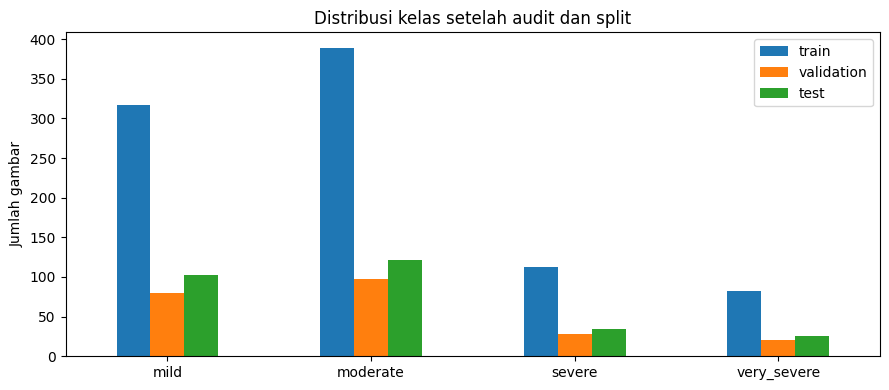

In [ ]:
canonical_train = clean_frame[clean_frame["canonical_split"] == "train"].copy()
test_df = clean_frame[clean_frame["canonical_split"] == "test"].copy()
if canonical_train.empty or test_df.empty:
    raise ValueError("Canonical split harus memiliki training dan test.")

train_df, val_df = train_test_split(
    canonical_train,
    test_size=CFG["validation_fraction"],
    stratify=canonical_train["level"],
    random_state=CFG["seed"],
)
train_df, val_df, test_df = [
    frame.reset_index(drop=True) for frame in (train_df, val_df, test_df)
]
for name, frame in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    if set(frame["level"]) != set(LABELS):
        raise ValueError(f"Split {name} tidak memiliki semua empat kelas.")

train_hashes, val_hashes, test_hashes = [
    set(frame["pixel_hash"]) for frame in (train_df, val_df, test_df)
]
assert train_hashes.isdisjoint(val_hashes)
assert train_hashes.isdisjoint(test_hashes)
assert val_hashes.isdisjoint(test_hashes)
assert len(train_df) + len(val_df) + len(test_df) == len(clean_frame)

split_manifest = pd.concat([
    frame.assign(split=name)
    for name, frame in [("train", train_df), ("validation", val_df), ("test", test_df)]
], ignore_index=True)
split_manifest.to_csv(RUN_DIR / "split_manifest.csv", index=False)

distribution = pd.DataFrame({
    name: frame["level"].value_counts().reindex(LABELS, fill_value=0)
    for name, frame in [("train", train_df), ("validation", val_df), ("test", test_df)]
})
distribution.index = CLASS_NAMES
display(distribution)
distribution.to_csv(RUN_DIR / "class_distribution.csv")
ax = distribution.plot.bar(figsize=(9, 4), rot=0)
ax.set_ylabel("Jumlah gambar")
ax.set_title("Distribusi kelas setelah audit dan split")
plt.tight_layout()
plt.savefig(RUN_DIR / "class_distribution.png", dpi=150)
plt.show()


## 6. Contoh gambar training

Contoh ini membantu memeriksa kualitas gambar, framing, dan apakah area lesi masih
terlihat setelah resize. Resolusi lebih besar dapat dicoba sebagai eksperimen
berikutnya, dengan pemilihan berdasarkan validation.


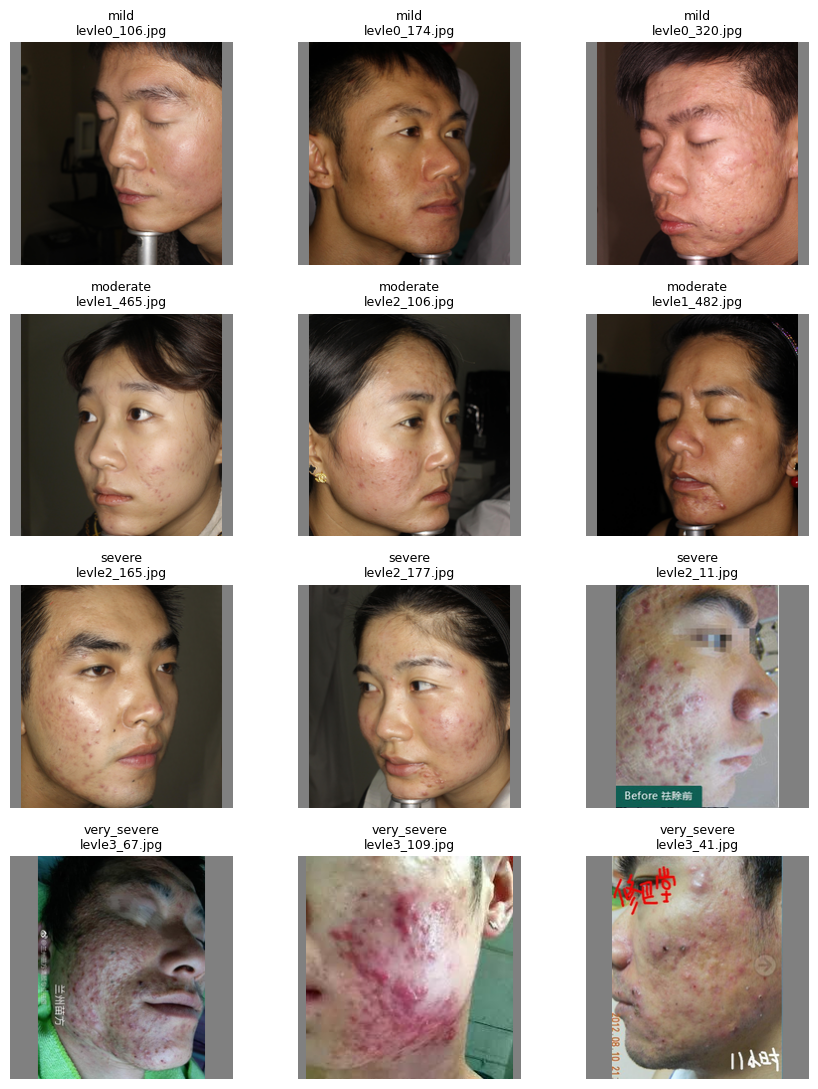

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(9, 11))
for level in LABELS:
    examples = train_df[train_df["level"] == level].sample(
        n=min(3, int((train_df["level"] == level).sum())), random_state=CFG["seed"]
    )
    for col, ax in enumerate(axes[level]):
        ax.axis("off")
        if col < len(examples):
            row = examples.iloc[col]
            with Image.open(row["image_path"]) as image:
                ax.imshow(image.copy())
            ax.set_title(f"{CLASS_NAMES[level]}\n{row['file_name']}", fontsize=9)
plt.tight_layout()
plt.show()


## 7. Transformasi dan DataLoader

Augmentasi hanya berlaku untuk training: horizontal flip, rotasi kecil, serta
perubahan brightness/contrast ringan. Tidak memakai crop agresif atau hue shift.
Validation dan test memakai preprocessing deterministik yang juga digunakan
saat inference. Label dan jumlah lesi tidak dimasukkan sebagai fitur model.

Normalisasi: `(pixel / 255 - 0.5) / 0.5`. Evaluasi tidak menggunakan augmentasi.
Tidak memakai oversampling bersamaan dengan weighted loss.


In [ ]:
def make_transforms(config):
    normalize = transforms.Normalize(mean=config["mean"], std=config["std"])
    train_transform = transforms.Compose([
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(
            degrees=5,
            interpolation=transforms.InterpolationMode.BILINEAR,
            fill=tuple(config["padding_rgb"]),
        ),
        transforms.ColorJitter(brightness=0.10, contrast=0.10),
        transforms.ToTensor(),
        normalize,
    ])
    eval_transform = transforms.Compose([transforms.ToTensor(), normalize])
    return train_transform, eval_transform

train_transform, eval_transform = make_transforms(CFG)

class AcneImageDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row["image_path"]) as image:
            image = image.convert("RGB")
            tensor = self.transform(image)
        return tensor, int(row["level"])

train_dataset = AcneImageDataset(train_df, train_transform)
val_dataset = AcneImageDataset(val_df, eval_transform)
test_dataset = AcneImageDataset(test_df, eval_transform)

loader_generator = torch.Generator().manual_seed(CFG["seed"])
loader_options = {
    "batch_size": CFG["batch_size"],
    "num_workers": CFG["num_workers"],
    "pin_memory": device.type == "cuda",
}
train_loader = DataLoader(
    train_dataset, shuffle=True, generator=loader_generator, **loader_options
)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_options)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_options)

images, targets = next(iter(val_loader))
print("Bentuk batch:", tuple(images.shape))
print("Label:", targets.tolist())
assert images.shape[1:] == (3, CFG["image_size"], CFG["image_size"])
assert torch.isfinite(images).all()


Bentuk batch: (16, 3, 224, 224)
Label: [0, 0, 1, 1, 1, 2, 0, 3, 0, 0, 1, 1, 2, 2, 1, 1]


## 8. Custom CNN dan inisialisasi dari nol

Empat blok berisi dua Conv2D 3×3, BatchNorm, ReLU, dan MaxPool.
Kanal bertambah **32 → 64 → 128 → 256**. Global average pooling membatasi jumlah
parameter classifier dibanding flatten seluruh feature map.

Classifier: Dense 128 → ReLU → Dropout 0,4 → Dense 4.
Model mengeluarkan **logits**, bukan softmax, karena cross-entropy menerima logits.
Softmax baru digunakan untuk menampilkan probabilitas prediksi.

Kaiming initialization untuk convolution, inisialisasi acak untuk linear.
Tidak ada `torchvision.models`, pemuatan bobot eksternal, atau layer yang dibekukan.


In [ ]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),
        )

    def forward(self, x):
        return self.layers(x)

class CustomAcneCNN(nn.Module):
    def __init__(self, num_classes=4, dropout=0.40):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3, 32),
            ConvBlock(32, 64),
            ConvBlock(64, 128),
            ConvBlock(128, 256),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes),
        )
        self.apply(self._initialize_weights)

    @staticmethod
    def _initialize_weights(layer):
        if isinstance(layer, nn.Conv2d):
            nn.init.kaiming_normal_(layer.weight, mode="fan_out", nonlinearity="relu")
        elif isinstance(layer, nn.BatchNorm2d):
            nn.init.ones_(layer.weight)
            nn.init.zeros_(layer.bias)
        elif isinstance(layer, nn.Linear):
            nn.init.normal_(layer.weight, mean=0.0, std=0.01)
            nn.init.zeros_(layer.bias)

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

model = CustomAcneCNN(num_classes=len(CLASS_NAMES), dropout=CFG["dropout"]).to(device)
total_parameters = sum(parameter.numel() for parameter in model.parameters())
print(model)
print(f"Total parameter: {total_parameters:,}")
assert all(parameter.requires_grad for parameter in model.parameters())

model.eval()
with torch.no_grad():
    sample_logits = model(images[:2].to(device))
assert sample_logits.shape == (min(2, len(images)), len(CLASS_NAMES))
assert torch.isfinite(sample_logits).all()
print("Forward pass berhasil:", tuple(sample_logits.shape))


CustomAcneCNN(
  (features): Sequential(
    (0): ConvBlock(
      (layers): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (layers): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2

## 9. Loss, optimizer, dan metrik

Bobot kelas `w_c = N_train / (4 × n_c)` dihitung hanya dari label training.
Weighted cross-entropy meningkatkan kontribusi kelas yang jarang muncul.

AdamW mulai pada LR 0,001. Scheduler menurunkan LR ketika validation macro-F1
berhenti meningkat. Early stopping dan checkpoint juga menggunakan metrik tersebut.
Macro-F1 memberi kontribusi setara untuk setiap kelas; accuracy saja kurang cukup.

Loss epoch dijumlahkan dengan denominator bobot target sehingga sesuai
definisi weighted cross-entropy. Recall tiap kelas juga dilaporkan.


In [ ]:
train_counts = np.bincount(train_df["level"].to_numpy(), minlength=len(CLASS_NAMES))
assert np.all(train_counts > 0)
class_weights = torch.tensor(
    len(train_df) / (len(CLASS_NAMES) * train_counts),
    dtype=torch.float32,
    device=device,
)
display(pd.DataFrame({
    "class": CLASS_NAMES, "train_count": train_counts,
    "loss_weight": class_weights.cpu().numpy(),
}))
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=CFG["learning_rate"], weight_decay=CFG["weight_decay"]
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=CFG["lr_patience"], min_lr=1e-6
)
USE_AMP = bool(CFG["use_amp"] and device.type == "cuda")
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

def calculate_metrics(y_true, y_pred):
    # MAE menghitung jarak antar-level, bukan selisih jumlah lesi.
    kappa = float(cohen_kappa_score(y_true, y_pred, labels=LABELS, weights="quadratic"))
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "quadratic_weighted_kappa": kappa if math.isfinite(kappa) else None,
        "grade_mae": float(np.abs(np.asarray(y_true) - np.asarray(y_pred)).mean()),
    }

def run_epoch(model, loader, criterion, device, optimizer=None, scaler=None,
              use_amp=False, gradient_clip=1.0, description="Epoch", show_progress=True):
    training = optimizer is not None
    if training and scaler is None:
        raise ValueError("Training memerlukan GradScaler, boleh dalam keadaan disabled.")
    model.train(training)
    numerator = 0.0
    denominator = 0.0
    all_targets, all_predictions, all_probabilities = [], [], []
    iterator = tqdm(loader, desc=description, leave=False, disable=not show_progress)
    with torch.set_grad_enabled(training):
        for batch_images, batch_targets in iterator:
            batch_images = batch_images.to(device, non_blocking=True)
            batch_targets = batch_targets.to(device, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                logits = model(batch_images)
                loss = criterion(logits, batch_targets)
            if not torch.isfinite(loss):
                raise FloatingPointError(f"Loss tidak finite pada {description}.")
            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=gradient_clip)
                scaler.step(optimizer)
                scaler.update()

            batch_denominator = (
                float(criterion.weight[batch_targets].sum().item())
                if criterion.weight is not None else float(len(batch_targets))
            )
            numerator += float(loss.item()) * batch_denominator
            denominator += batch_denominator
            probabilities = logits.detach().float().softmax(dim=1)
            all_probabilities.append(probabilities.cpu().numpy())
            all_predictions.append(probabilities.argmax(dim=1).cpu().numpy())
            all_targets.append(batch_targets.cpu().numpy())

    if not all_targets:
        raise ValueError("DataLoader kosong.")
    y_true = np.concatenate(all_targets)
    y_pred = np.concatenate(all_predictions)
    metrics = calculate_metrics(y_true, y_pred)
    metrics["loss"] = numerator / denominator
    return metrics, y_true, y_pred, np.concatenate(all_probabilities)


,class,train_count,loss_weight
0,mild,317,0.710568
1,moderate,389,0.579049
2,severe,113,1.993363
3,very_severe,82,2.746951


## 10. Training dan checkpoint terbaik

Sel berikut memulai training. Checkpoint disimpan hanya ketika validation macro-F1
meningkat. Test tidak dibaca selama training. Early stopping setelah 15 epoch tanpa
peningkatan; `epochs=100` merupakan batas maksimum, bukan janji model konvergen.

Output: `best_model.pt`, `history.csv`, `config.json`, `environment.json`,
dan `training_summary.json`. Checkpoint menyimpan bobot, urutan kelas, konfigurasi
preprocessing, serta metadata eksperimen. Ini checkpoint untuk inference,
bukan resume lengkap optimizer.


In [ ]:
def save_json(value, path):
    Path(path).write_text(
        json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False),
        encoding="utf-8",
    )

dataset_info = {
    "dataset_id": CFG["dataset_id"],
    "revision_requested": CFG["dataset_revision"],
    "fingerprint": DATASET_FINGERPRINT,
    "original_rows": len(raw_dataset),
    "clean_rows": len(clean_frame),
    "excluded_rows": len(exclusions),
    "train_rows": len(train_df),
    "validation_rows": len(val_df),
    "test_rows": len(test_df),
    "split_protocol": "canonical_test_after_exact_pixel_audit; stratified_validation_from_train",
    "duplicate_policy": "drop_conflicting_groups; keep_one_consistent_copy_test_priority",
}
save_json(CFG, RUN_DIR / "config.json")
save_json({"python": platform.python_version(), **VERSIONS}, RUN_DIR / "environment.json")
save_json(dataset_info, RUN_DIR / "dataset_info.json")

def fit_model(model, train_loader, val_loader, criterion, optimizer, scheduler,
              scaler, device, config, run_dir, dataset_info):
    checkpoint_path = Path(run_dir) / "best_model.pt"
    history = []
    best_f1 = -1.0
    best_epoch = 0
    bad_epochs = 0
    use_amp = bool(config["use_amp"] and device.type == "cuda")
    for epoch in range(1, config["epochs"] + 1):
        used_lr = float(optimizer.param_groups[0]["lr"])
        train_stats, _, _, _ = run_epoch(
            model, train_loader, criterion, device, optimizer=optimizer, scaler=scaler,
            use_amp=use_amp, gradient_clip=config["gradient_clip"],
            description=f"Train {epoch}/{config['epochs']}",
        )
        val_stats, _, _, _ = run_epoch(
            model, val_loader, criterion, device, use_amp=use_amp,
            description=f"Validation {epoch}/{config['epochs']}",
        )
        entry = {"epoch": epoch, "learning_rate": used_lr}
        entry.update({"train_" + key: value for key, value in train_stats.items()})
        entry.update({"val_" + key: value for key, value in val_stats.items()})
        history.append(entry)
        pd.DataFrame(history).to_csv(Path(run_dir) / "history.csv", index=False)

        improved = val_stats["macro_f1"] > best_f1
        if improved:
            best_f1 = val_stats["macro_f1"]
            best_epoch = epoch
            bad_epochs = 0
            checkpoint = {
                "architecture": "custom_acne_cnn_v1",
                "state_dict": {
                    key: value.detach().cpu()
                    for key, value in model.state_dict().items()
                },
                "config": dict(config),
                "class_names": list(CLASS_NAMES),
                "class_weights": criterion.weight.detach().cpu(),
                "epoch": epoch,
                "validation_metrics": val_stats,
                "dataset_info": dict(dataset_info),
                "library_versions": dict(VERSIONS),
            }
            temporary_path = checkpoint_path.with_suffix(".tmp")
            torch.save(checkpoint, temporary_path)
            temporary_path.replace(checkpoint_path)
        else:
            bad_epochs += 1
        scheduler.step(val_stats["macro_f1"])
        status = " | checkpoint disimpan" if improved else ""
        print(
            f"Epoch {epoch:03d} | LR {used_lr:.2e} | "
            f"train loss {train_stats['loss']:.4f}, F1 {train_stats['macro_f1']:.4f} | "
            f"val loss {val_stats['loss']:.4f}, F1 {val_stats['macro_f1']:.4f}"
            + status
        )
        if bad_epochs >= config["early_stopping_patience"]:
            print(f"Early stopping: {bad_epochs} epoch tanpa peningkatan validation macro-F1.")
            break

    summary = {
        "epochs_completed": len(history),
        "best_epoch": best_epoch,
        "best_validation_macro_f1": best_f1,
        "checkpoint_path": str(checkpoint_path),
    }
    save_json(summary, Path(run_dir) / "training_summary.json")
    return pd.DataFrame(history), checkpoint_path, summary

history_df, BEST_CHECKPOINT, training_summary = fit_model(
    model, train_loader, val_loader, criterion, optimizer, scheduler,
    scaler, device, CFG, RUN_DIR, dataset_info,
)
display(pd.DataFrame([training_summary]))


Train 1/100:   0%|          | 0/57 [00:00<?, ?it/s]

Validation 1/100:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 001 | LR 1.00e-03 | train loss 1.2844, F1 0.3427 | val loss 1.1916, F1 0.2847 | checkpoint disimpan


Train 2/100:   0%|          | 0/57 [00:00<?, ?it/s]

Validation 2/100:   0%|          | 0/15 [00:00<?, ?it/s]

...

Epoch 047 | LR 1.25e-04 | train loss 0.6250, F1 0.6989 | val loss 0.7280, F1 0.6798


Train 48/100:   0%|          | 0/57 [00:00<?, ?it/s]

Validation 48/100:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 048 | LR 1.25e-04 | train loss 0.6375, F1 0.7269 | val loss 0.6919, F1 0.6793
Early stopping: 15 epoch tanpa peningkatan validation macro-F1.


,epochs_completed,best_epoch,best_validation_macro_f1,checkpoint_path
0,48,33,0.732376,/content/acne04_runs/run_20261018_172805_06108...


## 11. Kurva training

Bandingkan train dan validation. Train F1 dihitung saat dropout/augmentasi aktif dan
bobot berubah sepanjang epoch, sehingga bukan evaluasi training set yang deterministik.
Jika train membaik tetapi validation memburuk, periksa overfitting.

Selanjutnya ubah hyperparameter berdasarkan validation. Jangan memilih konfigurasi
berdasarkan test lalu melaporkan skor test tersebut sebagai evaluasi independen.


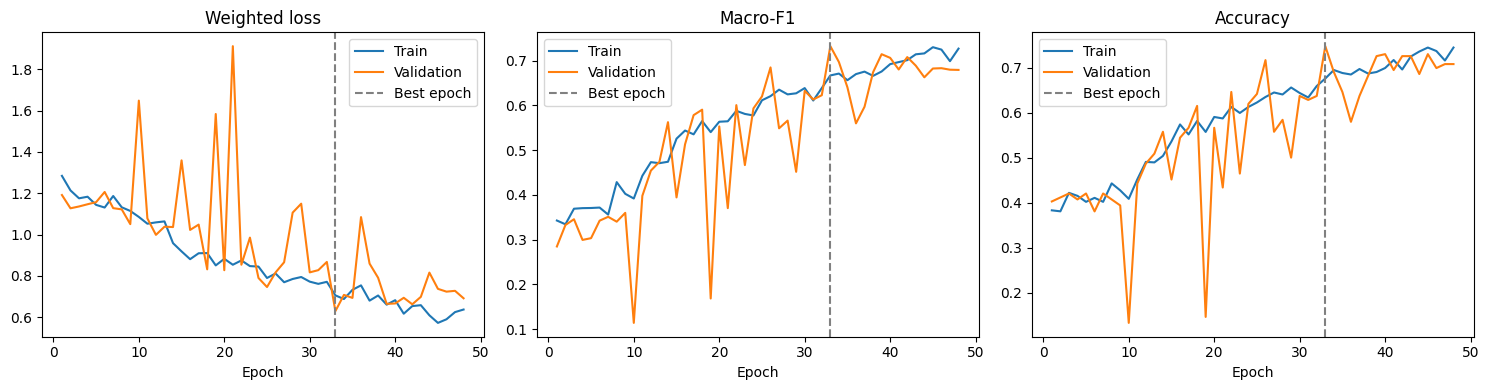

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in zip(
    axes, ["loss", "macro_f1", "accuracy"], ["Weighted loss", "Macro-F1", "Accuracy"]
):
    ax.plot(history_df["epoch"], history_df["train_" + metric], label="Train")
    ax.plot(history_df["epoch"], history_df["val_" + metric], label="Validation")
    ax.axvline(training_summary["best_epoch"], color="gray", linestyle="--", label="Best epoch")
    ax.set_xlabel("Epoch")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.savefig(RUN_DIR / "training_curves.png", dpi=150)
plt.show()


## 12. Reload checkpoint dan evaluasi test

Bobot yang digunakan adalah checkpoint validation terbaik, bukan otomatis epoch terakhir.
Test dibaca setelah training selesai. Laporkan macro-F1, balanced accuracy, recall
tiap kelas, quadratic weighted kappa, dan grade MAE bersama accuracy.

Bandingkan juga dengan prediksi konstan kelas terbanyak dari **training**.
Probabilitas softmax bukan probabilitas klinis yang sudah dikalibrasi.
Sel ini akan mencatat hasil nyata saat kamu menjalankannya; notebook tidak berisi
skor training yang diasumsikan.


In [ ]:
def load_trained_model(checkpoint_path, target_device):
    # Muat hanya checkpoint yang dibuat notebook ini / berasal dari sumber tepercaya.
    checkpoint = torch.load(
        checkpoint_path, map_location="cpu", weights_only=True
    )
    if checkpoint["architecture"] != "custom_acne_cnn_v1":
        raise ValueError("Arsitektur checkpoint tidak cocok.")
    names = checkpoint["class_names"]
    if names != CLASS_NAMES:
        raise ValueError(f"Urutan kelas checkpoint berbeda: {names}")
    trained_model = CustomAcneCNN(
        num_classes=len(names), dropout=checkpoint["config"]["dropout"]
    )
    trained_model.load_state_dict(checkpoint["state_dict"], strict=True)
    trained_model = trained_model.to(target_device).eval()
    return trained_model, checkpoint

best_model, best_checkpoint = load_trained_model(BEST_CHECKPOINT, device)
test_criterion = nn.CrossEntropyLoss(
    weight=best_checkpoint["class_weights"].to(device)
)
test_metrics, y_test, y_test_pred, test_probabilities = run_epoch(
    best_model, test_loader, test_criterion, device,
    use_amp=USE_AMP, description="Evaluasi test",
)
majority_class = int(train_counts.argmax())
majority_predictions = np.full_like(y_test, fill_value=majority_class)
majority_metrics = calculate_metrics(y_test, majority_predictions)
display(pd.DataFrame(
    [test_metrics, majority_metrics],
    index=["Custom CNN", f"Baseline konstan: {CLASS_NAMES[majority_class]}"],
))

report = classification_report(
    y_test, y_test_pred, labels=LABELS, target_names=CLASS_NAMES,
    output_dict=True, zero_division=0,
)
print(classification_report(
    y_test, y_test_pred, labels=LABELS, target_names=CLASS_NAMES,
    digits=4, zero_division=0,
))
save_json({
    "model": test_metrics,
    "majority_baseline": majority_metrics,
    "majority_class_from_training": CLASS_NAMES[majority_class],
    "best_epoch": best_checkpoint["epoch"],
    "test_rows": len(test_df),
}, RUN_DIR / "test_metrics.json")
save_json(report, RUN_DIR / "classification_report.json")
pd.DataFrame(report).transpose().to_csv(RUN_DIR / "classification_report.csv")

predictions_df = test_df[["file_name", "pixel_hash", "level", "severity"]].copy()
assert np.array_equal(predictions_df["level"].to_numpy(), y_test)
predictions_df["predicted_level"] = y_test_pred
predictions_df["predicted_severity"] = [CLASS_NAMES[level] for level in y_test_pred]
predictions_df["softmax_score"] = test_probabilities.max(axis=1)
for level, name in enumerate(CLASS_NAMES):
    predictions_df["probability_" + name] = test_probabilities[:, level]
predictions_df["correct"] = y_test == y_test_pred
predictions_df.to_csv(RUN_DIR / "test_predictions.csv", index=False)


Evaluasi test:   0%|          | 0/18 [00:00<?, ?it/s]

,accuracy,macro_f1,balanced_accuracy,quadratic_weighted_kappa,grade_mae,loss
Custom CNN,0.728873,0.698750,0.738203,0.832494,0.285211,0.608634
Baseline konstan: moderate,0.426056,0.149383,0.250000,0.000000,0.665493,NaN


              precision    recall  f1-score   support

        mild     0.8404    0.7745    0.8061       102
    moderate     0.7522    0.7025    0.7265       121
      severe     0.4737    0.5143    0.4932        35
 very_severe     0.6410    0.9615    0.7692        26

    accuracy                         0.7289       284
   macro avg     0.6768    0.7382    0.6987       284
weighted avg     0.7394    0.7289    0.7302       284



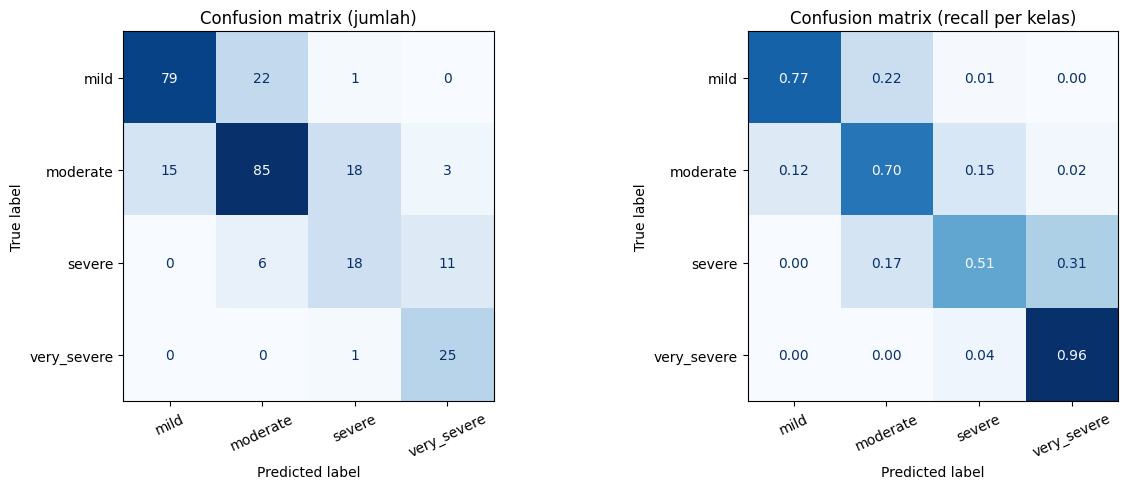

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, normalize, title in zip(
    axes, [None, "true"], ["Confusion matrix (jumlah)", "Confusion matrix (recall per kelas)"]
):
    matrix = confusion_matrix(y_test, y_test_pred, labels=LABELS, normalize=normalize)
    ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(
        ax=ax, cmap="Blues", colorbar=False,
        values_format="d" if normalize is None else ".2f",
    )
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.savefig(RUN_DIR / "test_confusion_matrix.png", dpi=150)
plt.show()


## 13. Contoh salah prediksi

Periksa apakah kesalahan terutama terjadi pada kelas berdekatan atau jauh.
Contoh diurutkan menurut softmax tertinggi di antara kesalahan. Analisis ini
untuk pelaporan; tuning lanjutan memerlukan evaluasi independen yang baru.


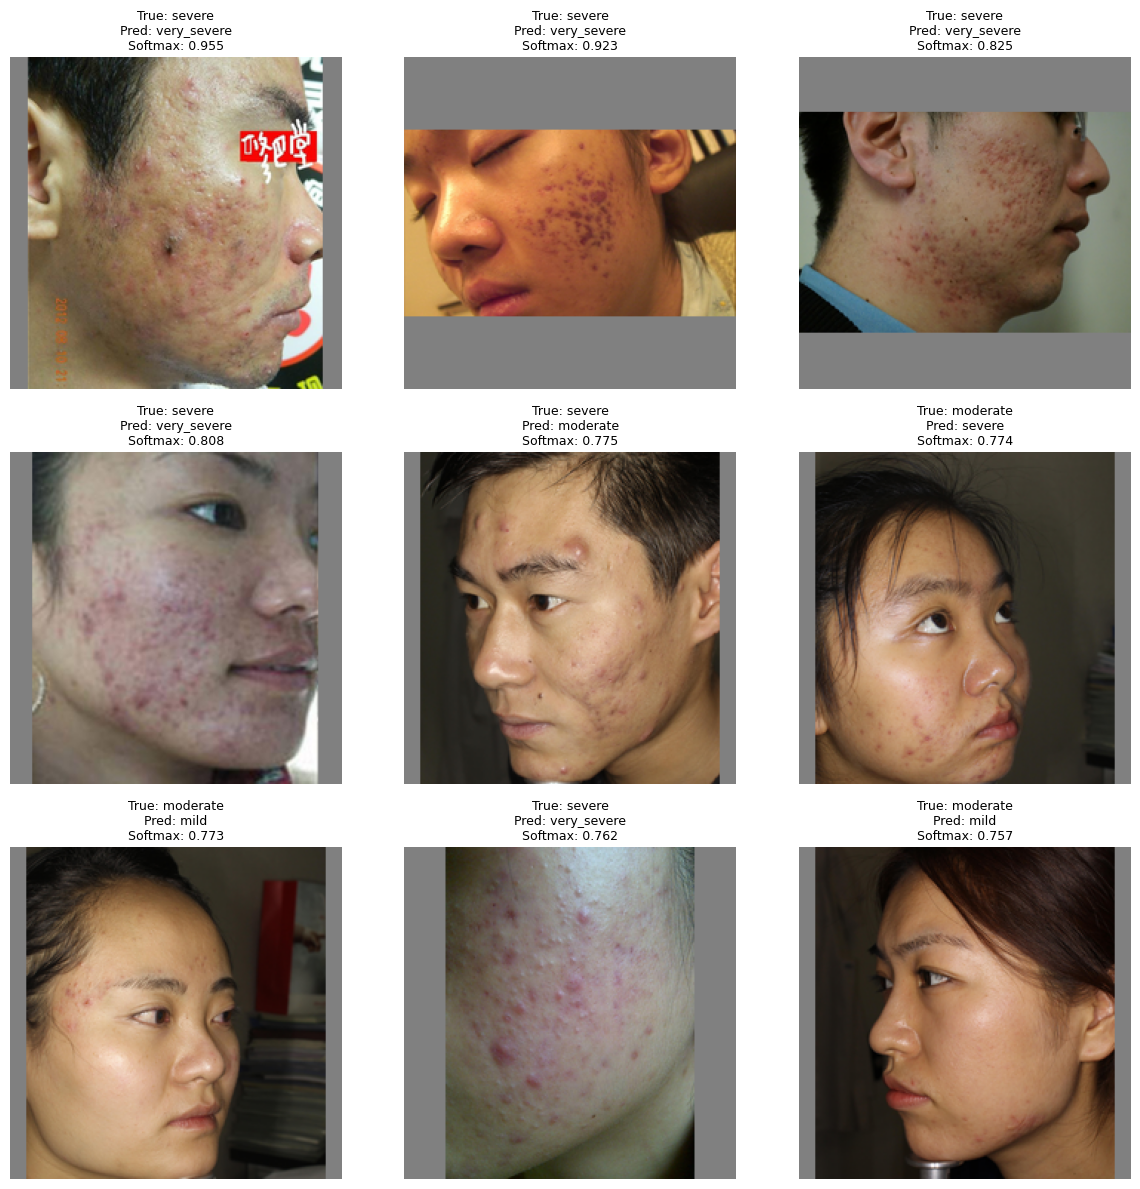

In [ ]:
errors = predictions_df[~predictions_df["correct"]].sort_values(
    "softmax_score", ascending=False
).head(9)
if errors.empty:
    print("Tidak ada salah prediksi pada test ini.")
else:
    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    for ax in axes.flat:
        ax.axis("off")
    for ax, (index, row) in zip(axes.flat, errors.iterrows()):
        with Image.open(test_df.iloc[index]["image_path"]) as image:
            ax.imshow(image.copy())
        ax.set_title(
            f"True: {row['severity']}\nPred: {row['predicted_severity']}\n"
            f"Softmax: {row['softmax_score']:.3f}",
            fontsize=9,
        )
    plt.tight_layout()
    plt.savefig(RUN_DIR / "test_misclassifications.png", dpi=150)
    plt.show()


## 14. Prediksi gambar baru

Preprocessing diambil dari checkpoint: RGB, orientasi EXIF, letterbox,
normalisasi, serta urutan kelas yang sama dengan training.
Isi `IMAGE_PATH` dengan path foto yang sudah diupload ke Colab atau disimpan lokal.

Untuk sesi baru, jalankan sel import, definisi `letterbox_image`, `make_transforms`,
`CustomAcneCNN`, dan `load_trained_model` sebelum memakai fungsi berikut.
Tidak perlu download dataset atau training ulang jika checkpoint sudah tersedia.
Gunakan `load_trained_model(Path(".../best_model.pt"), device)`.

Foto tanpa jerawat, foto selain wajah, atau foto dengan framing berbeda tetap akan
dipaksa menjadi salah satu empat kelas. Skor softmax tinggi tidak membuktikan
foto sesuai distribusi dataset atau prediksi benar.


In [ ]:
@torch.inference_mode()
def predict_image(image_path, trained_model, checkpoint, target_device):
    config = checkpoint["config"]
    _, inference_transform = make_transforms(config)
    with Image.open(image_path) as image:
        prepared = letterbox_image(
            image, config["image_size"], config["padding_rgb"]
        )
    tensor = inference_transform(prepared).unsqueeze(0).to(target_device)
    trained_model.eval()
    probabilities = trained_model(tensor).float().softmax(dim=1)[0].cpu().numpy()
    predicted_level = int(probabilities.argmax())
    probability_table = pd.DataFrame({
        "level": list(range(len(checkpoint["class_names"]))),
        "severity": checkpoint["class_names"],
        "softmax_probability": probabilities,
    })
    result = {
        "predicted_level": predicted_level,
        "predicted_severity": checkpoint["class_names"][predicted_level],
        "softmax_score": float(probabilities[predicted_level]),
    }
    return result, probability_table, prepared

IMAGE_PATH = None  # Contoh Colab: "/content/foto_jerawat.jpg"
if IMAGE_PATH is not None:
    result, probability_table, prepared_image = predict_image(
        IMAGE_PATH, best_model, best_checkpoint, device
    )
    print(result)
    display(probability_table)
    plt.figure(figsize=(5, 5))
    plt.imshow(prepared_image)
    plt.axis("off")
    plt.title(f"{result['predicted_severity']} — softmax {result['softmax_score']:.3f}")
    plt.show()
else:
    print("Isi IMAGE_PATH untuk memprediksi foto baru.")


Isi IMAGE_PATH untuk memprediksi foto baru.


## 15. Simpan hasil dan tulis laporan

Folder run berisi checkpoint, konfigurasi, manifest split, hasil audit, kurva,
classification report, metrik, dan prediksi test. Di Colab, download folder
atau pindahkan ke Drive sebelum runtime ditutup. File ZIP tidak mencakup dataset
atau cache gambar, sehingga ukurannya lebih kecil.

Untuk laporan, sertakan jumlah data setelah audit, distribusi kelas per split,
seed, versi library, arsitektur, jumlah parameter, hyperparameter, epoch terbaik,
serta metrik tiap kelas. Catat bahwa model trained from scratch dan skor belum
membuktikan generalisasi pada pasien, perangkat, atau kondisi foto yang berbeda.

Pengembangan berikutnya dapat membandingkan beberapa seed atau CORAL dengan
backbone yang sama; lakukan pemilihan eksperimen menggunakan validation.


In [ ]:
import shutil

archive_path = shutil.make_archive(str(RUN_DIR), "zip", root_dir=RUN_DIR)
print("Folder hasil:", RUN_DIR)
print("Checkpoint:", BEST_CHECKPOINT)
print("ZIP hasil:", archive_path)
print("Untuk Colab, download ZIP melalui panel Files.")


Folder hasil: /content/acne04_runs/run_20261018_172805_061084
Checkpoint: /content/acne04_runs/run_20261018_172805_061084/best_model.pt
ZIP hasil: /content/acne04_runs/run_20261018_172805_061084.zip
Untuk Colab, download ZIP melalui panel Files.
